# RadioML 2016.10a: Dataset Exploration & Signal Visualization
## Automatic Modulation Classification (AMC) - Exploratory Data Analysis

---

### Overview & Objectives
**Automatic Modulation Classification (AMC)** is a core capability in modern **Cognitive Radio (CR)**, dynamic spectrum access, electronic surveillance, and software-defined communications. AMC algorithms automatically identify the modulation format of an intercepted radio signal without prior knowledge of the transmitted parameters or manual operator intervention.

Before deploying deep learning architectures (e.g., Convolutional Neural Networks, ResNets, or Recurrent Networks), it is essential to deeply understand the physical characteristics, mathematical representation, and channel degradation mechanisms present in the dataset.

This notebook provides a comprehensive exploratory data analysis of the foundational **RadioML 2016.10a** dataset (`RML2016.10a_dict.pkl`), covering:
1. **Dataset Architecture & Representation**: In-phase ($I$) and Quadrature ($Q$) decomposition, tensor dimensions, SNR range, and class distributions.
2. **Time-Domain Signal Visualization**: In-Phase ($I$) and Quadrature ($Q$) waveforms across varying Signal-to-Noise Ratios (-10 dB, 0 dB, +10 dB, +18 dB) and modulation families.
3. **Constellation Diagrams (Phase Space Dynamics)**: Two-dimensional $I$-$Q$ scatter representations across modulation schemes and physical Gaussian dispersion under noise.
4. **Frequency-Domain Spectral Analysis (FFT)**: Complex baseband Fast Fourier Transform, Power Spectral Density (PSD), spectral symmetry/asymmetry, and a critical evaluation of why frequency analysis alone is insufficient for modulation classification.
5. **Scientific Synthesis**: Summary of physical observations and their direct implications for Deep Learning-based AMC.

> **Note**: This notebook is dedicated strictly to dataset understanding, signal processing theory, and visual exploration. No model training or dataset splitting is performed in this notebook.


In [1]:
import os
import sys
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.fft as fft
from scipy import signal

# Configure matplotlib for publication-quality, consistent rendering
os.environ['MPLCONFIGDIR'] = os.environ.get('MPLCONFIGDIR', '/tmp/matplotlib')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['lines.linewidth'] = 1.2
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

# Set fixed random seed for visual reproducibility
np.random.seed(42)

print("Environment successfully initialized.")
print(f"NumPy version: {np.__version__}")
print(f"Matplotlib backend configured.")


Environment successfully initialized.
NumPy version: 2.5.4
Matplotlib backend configured.


## 1. Dataset Description & Mathematical Formulation

### 1.1 In-Phase ($I$) and Quadrature ($Q$) Representation
In radio frequency (RF) communications, a passband signal centered at carrier frequency $f_c$ is expressed as:

$$s_{\text{RF}}(t) = I(t) \cos(2\pi f_c t) - Q(t) \sin(2\pi f_c t) = \text{Re}\left\{ s_{\text{bb}}(t) e^{j 2\pi f_c t} \right\}$$

where:
* **$I(t)$ (In-Phase component)**: The projection of the signal onto the cosine carrier $\cos(2\pi f_c t)$.
* **$Q(t)$ (Quadrature component)**: The projection onto the sine carrier $-\sin(2\pi f_c t)$, orthogonal ($90^\circ$ out of phase) to $I(t)$.
* **$s_{\text{bb}}(t) = I(t) + j Q(t)$**: The **equivalent complex baseband analytic signal**.

Modern **Software-Defined Radios (SDR)** employ direct quadrature downconversion (I/Q demodulation) to translate the RF signal from gigahertz frequencies down to baseband ($f_c \to 0$). This removes the high-frequency carrier while retaining $100\%$ of the instantaneous amplitude $A(t)$ and phase $\phi(t)$ information:

$$A(t) = \sqrt{I^2(t) + Q^2(t)}, \qquad \phi(t) = \arctan2\left(Q(t), I(t)\right)$$

### 1.2 The RadioML 2016.10a Dataset
Generated by O'Shea and West (2016) using GNU Radio, **RadioML 2016.10a** models realistic synthetic channel impairments:
* **Thermal Noise**: Additive White Gaussian Noise (AWGN) across a 20-level SNR range ($-20\text{ dB}$ to $+18\text{ dB}$).
* **Carrier Frequency Offset (CFO)**: Frequency drift between transmitter and receiver local oscillators ($e^{j 2\pi \Delta f t}$).
* **Sample Rate Offset (SRO)**: Clock jitter and timing offsets.
* **Multipath Fading**: Selective fading channels (Rician and Rayleigh channels).

Let us load the dataset pickle file and inspect its programmatic structure.


In [2]:
dataset_path = 'RML2016.10a_dict.pkl'

# Check file existence in local directory or parent directory
if not os.path.exists(dataset_path):
    # Try alternative relative paths if executed from different working directory
    alt_path = os.path.join('Automatic-Modulation-Classification-AMC-using-Deep-Learning', dataset_path)
    if os.path.exists(alt_path):
        dataset_path = alt_path

print(f"Loading dataset from: {dataset_path}")
file_size_mb = os.path.getsize(dataset_path) / (1024 * 1024)
print(f"Dataset archive size: {file_size_mb:.2f} MB")

# Load dictionary using latin1 encoding (required for Python 2 to Python 3 pickle compatibility)
with open(dataset_path, 'rb') as f:
    dataset = pickle.load(f, encoding='latin1')

print(f"Successfully loaded {len(dataset.keys())} dictionary entries.")


Loading dataset from: RML2016.10a_dict.pkl
Dataset archive size: 611.23 MB
Successfully loaded 220 dictionary entries.


### 1.3 Structural Breakdown & Tensor Dimensions

The loaded object is a Python dictionary where each key is a 2-element tuple:
$$\text{Key} = (\text{Modulation Name}, \text{SNR in dB})$$

Each key maps to a NumPy array containing raw I/Q signal observations. Let us programmatically extract:
1. The unique modulation classes and their communication categories.
2. The complete range of Signal-to-Noise Ratios (SNRs).
3. The exact tensor dimensions and what each dimension physically represents.
4. Total sample counts and memory utilization.


In [3]:
# Extract unique modulation labels and SNR levels
keys = list(dataset.keys())
modulations = sorted(list(set(k[0] for k in keys)))
snr_levels = sorted(list(set(k[1] for k in keys)))

sample_key = keys[0]
sample_tensor = dataset[sample_key]

# Compute total dataset statistics
samples_per_slice = sample_tensor.shape[0]
n_channels = sample_tensor.shape[1]
n_time_steps = sample_tensor.shape[2]
total_slices = len(keys)
total_samples = total_slices * samples_per_slice
total_elements = total_samples * n_channels * n_time_steps
memory_mb = (total_elements * sample_tensor.itemsize) / (1024 * 1024)

print("=" * 65)
print("             RadioML 2016.10a DATASET SPECIFICATIONS")
print("=" * 65)
print(f"Modulation Classes ({len(modulations)}): {modulations}")
print(f"SNR Levels in dB   ({len(snr_levels)}): {snr_levels}")
print(f"Dictionary Entries : {total_slices} (11 modulations x 20 SNRs)")
print(f"Per-Slice Shape    : {sample_tensor.shape} (Samples, Channels, Time)")
print(f"Data Type          : {sample_tensor.dtype}")
print("-" * 65)
print(f"Total Signal Frames: {total_samples:,} observations")
print(f"Total I/Q Samples  : {total_elements:,} scalar floating-point values")
print(f"Total Array Memory : {memory_mb:.2f} MB in RAM")
print("=" * 65)

# Dimension semantics explanation
print("\nDIMENSIONAL SEMANTICS OF EACH TENSOR (N_samples, Channels, Length):")
print(f" * Dimension 0 ({samples_per_slice:4d}): Observation index (1,000 independent signal bursts)")
print(f" * Dimension 1 ({n_channels:4d}): Orthogonal Quadrature Channels (Index 0 = In-Phase 'I', Index 1 = Quadrature 'Q')")
print(f" * Dimension 2 ({n_time_steps:4d}): Time steps (128 discrete sampling instants at baseband sample rate fs)")



             RadioML 2016.10a DATASET SPECIFICATIONS


Modulation Classes (11): ['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']

SNR Levels in dB   (20): [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]

Dictionary Entries : 220 (11 modulations x 20 SNRs)

Per-Slice Shape    : (1000, 2, 128) (Samples, Channels, Time)

Data Type          : float32

-----------------------------------------------------------------

Total Signal Frames: 220,000 observations

Total I/Q Samples  : 56,320,000 scalar floating-point values

Total Array Memory : 214.84 MB in RAM




DIMENSIONAL SEMANTICS OF EACH TENSOR (N_samples, Channels, Length):

 * Dimension 0 (1000): Observation index (1,000 independent signal bursts)

 * Dimension 1 (   2): Orthogonal Quadrature Channels (Index 0 = In-Phase 'I', Index 1 = Quadrature 'Q')

 * Dimension 2 ( 128): Time steps (128 discrete sampling instants at baseband sample rate fs)



### 1.4 Modulation Families & Dataset Balance

The 11 modulation schemes in RadioML 2016.10a span both **digital** and **analog** communications:

| Family | Modulations | Description | Constellation Nature |
| :--- | :--- | :--- | :--- |
| **Phase Shift Keying (PSK)** | `BPSK`, `QPSK`, `8PSK` | Information encoded into carrier phase $\theta_k$ | Discrete points on a circle |
| **Quadrature Amplitude Modulation (QAM)** | `QAM16`, `QAM64` | Information encoded in both amplitude and phase | 2D rectangular lattice grid |
| **Frequency Shift Keying (FSK)** | `CPFSK`, `GFSK` | Information encoded in instantaneous frequency shifts | Constant-envelope trajectory |
| **Pulse Amplitude Modulation (PAM)** | `PAM4` | Multi-level amplitude shifts along a single phase axis | 1D discrete collinear points |
| **Analog Audio Modulation** | `AM-DSB`, `AM-SSB`, `WBFM` | Analog voice/audio signals modulated on carrier | Continuous trajectories |

A critical property of RadioML 2016.10a is that it is **strictly balanced**: exactly 1,000 frames exist for every `(modulation, SNR)` pair. This prevents any majority-class bias during evaluation.


Distribution verification: Perfect class and SNR balance confirmed.



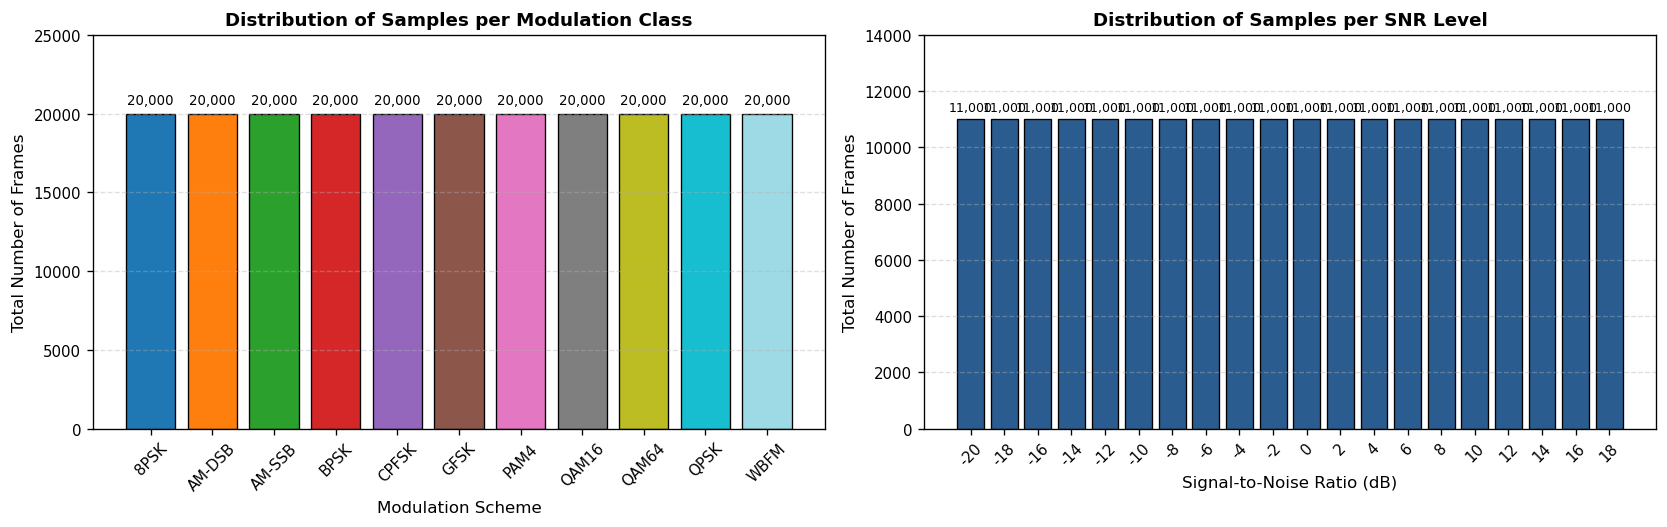

In [4]:
# Verify sample counts across all modulations and SNRs
mod_counts = {m: 0 for m in modulations}
snr_counts = {s: 0 for s in snr_levels}

for (m, s), data_slice in dataset.items():
    count = data_slice.shape[0]
    mod_counts[m] += count
    snr_counts[s] += count

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Subplot 1: Distribution per Modulation
ax1 = axes[0]
colors_mod = plt.cm.tab20(np.linspace(0, 1, len(modulations)))
bars1 = ax1.bar(modulations, [mod_counts[m] for m in modulations], color=colors_mod, edgecolor='black', linewidth=0.8)
ax1.set_title("Distribution of Samples per Modulation Class", fontweight='bold')
ax1.set_xlabel("Modulation Scheme")
ax1.set_ylabel("Total Number of Frames")
ax1.set_ylim(0, 25000)
ax1.grid(True, axis='y', alpha=0.4)
ax1.tick_params(axis='x', rotation=45)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 400, f"{yval:,}", ha='center', va='bottom', fontsize=8)

# Subplot 2: Distribution per SNR Level
ax2 = axes[1]
bars2 = ax2.bar([str(s) for s in snr_levels], [snr_counts[s] for s in snr_levels], color='#2b5c8f', edgecolor='black', linewidth=0.8)
ax2.set_title("Distribution of Samples per SNR Level", fontweight='bold')
ax2.set_xlabel("Signal-to-Noise Ratio (dB)")
ax2.set_ylabel("Total Number of Frames")
ax2.set_ylim(0, 14000)
ax2.grid(True, axis='y', alpha=0.4)
ax2.tick_params(axis='x', rotation=45)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 200, f"{yval:,}", ha='center', va='bottom', fontsize=7.5)

plt.tight_layout()
plt.show()

print("Distribution verification: Perfect class and SNR balance confirmed.")


---
## 2. Time-Domain Visualization: $I(t)$ and $Q(t)$ Waveforms

### 2.1 The Additive White Gaussian Noise (AWGN) Degradation Model
When an RF signal traverses a wireless channel, it is corrupted by thermal noise originating from the receiver front-end amplifiers:

$$r[n] = s[n] + w[n]$$

where:
* $s[n] = I[n] + j Q[n]$ is the clean pulse-shaped transmitted signal.
* $w[n] = w_I[n] + j w_Q[n]$ is complex zero-mean Additive White Gaussian Noise:
  $$w_I[n], w_Q[n] \sim \mathcal{N}\left(0, \frac{\sigma_w^2}{2}\right)$$
* The **Signal-to-Noise Ratio (SNR)** in decibels is defined as:
  $$\text{SNR}_{\text{dB}} = 10 \log_{10}\left(\frac{P_s}{P_w}\right) = 10 \log_{10}\left(\frac{\mathbb{E}[|s[n]|^2]}{\sigma_w^2}\right)$$

### 2.2 Time-Domain Inspection Across SNR Levels
To observe how noise affects the waveform, we examine the **same modulation (QPSK)** across four key SNR operating points:
* **$-10\text{ dB}$ (Severe Noise Regime)**: Noise power is **10 times greater** than signal power ($P_w / P_s = 10$).
* **$0\text{ dB}$ (Equal Power Boundary)**: Signal power equals noise power ($P_s = P_w$).
* **$+10\text{ dB}$ (Clean Operational Regime)**: Signal power is **10 times greater** than noise power.
* **$+18\text{ dB}$ (Pristine High-Fidelity Signal)**: Signal power is **63 times greater** than noise power ($P_s / P_w \approx 63.1$).

We will display the In-Phase ($I$) and Quadrature ($Q$) components in **separate subplots** with consistent vertical scaling for an objective, rigorous comparison.


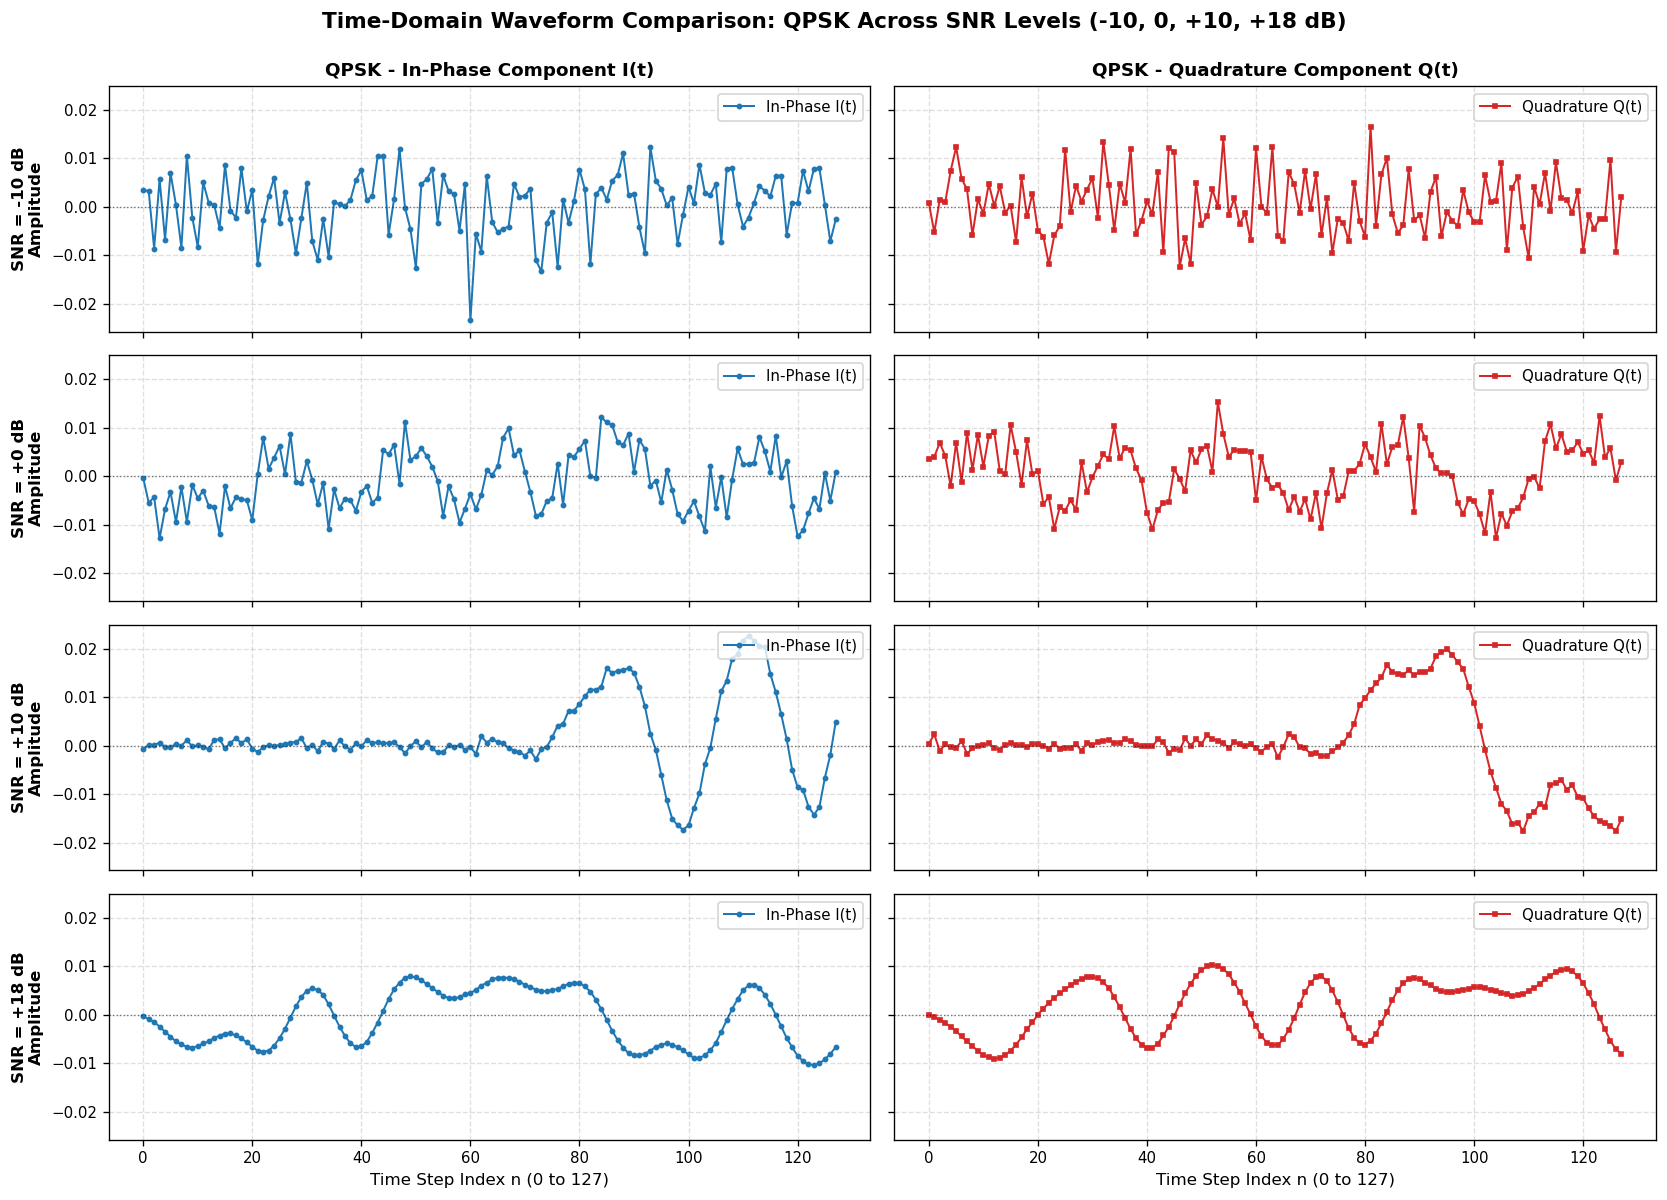

In [5]:
target_mod = 'QPSK'
target_snrs = [-10, 0, 10, 18]
sample_idx = 0  # Inspect consistent frame index across SNRs

fig, axes = plt.subplots(len(target_snrs), 2, figsize=(14, 10), sharex=True, sharey=True)

time_steps = np.arange(128)

for row, snr in enumerate(target_snrs):
    raw_frame = dataset[(target_mod, snr)][sample_idx]
    I_comp = raw_frame[0]
    Q_comp = raw_frame[1]
    
    # Left Subplot: In-Phase Component (I)
    ax_i = axes[row, 0]
    ax_i.plot(time_steps, I_comp, color='#1f77b4', marker='o', markersize=2.5, label='In-Phase I(t)')
    ax_i.axhline(0, color='black', linestyle=':', alpha=0.5, linewidth=0.8)
    ax_i.set_ylabel(f"SNR = {snr:+2d} dB\nAmplitude", fontweight='bold')
    ax_i.grid(True, alpha=0.4)
    ax_i.legend(loc='upper right')
    if row == 0:
        ax_i.set_title(f"{target_mod} - In-Phase Component I(t)", fontweight='bold', fontsize=11)
        
    # Right Subplot: Quadrature Component (Q)
    ax_q = axes[row, 1]
    ax_q.plot(time_steps, Q_comp, color='#d62728', marker='s', markersize=2.5, label='Quadrature Q(t)')
    ax_q.axhline(0, color='black', linestyle=':', alpha=0.5, linewidth=0.8)
    ax_q.grid(True, alpha=0.4)
    ax_q.legend(loc='upper right')
    if row == 0:
        ax_q.set_title(f"{target_mod} - Quadrature Component Q(t)", fontweight='bold', fontsize=11)

# Set common labels on bottom row
axes[-1, 0].set_xlabel("Time Step Index n (0 to 127)")
axes[-1, 1].set_xlabel("Time Step Index n (0 to 127)")

plt.suptitle(f"Time-Domain Waveform Comparison: {target_mod} Across SNR Levels (-10, 0, +10, +18 dB)", 
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### 2.3 Physical Explanation of Noise Degradation in Time-Domain

Observing the $I(t)$ and $Q(t)$ waveforms across SNR levels reveals the physical mechanics of channel corruption:

1. **At $-10\text{ dB}$**:
   * Noise power completely masks the carrier phase and symbol transitions. The waveform exhibits high-frequency stochastic jitter with large variance.
   * Zero-crossing points and amplitude plateaus are completely randomized. To an observer or a linear matched filter, the signal is indistinguishable from pure Gaussian white noise.
   * This explains why Automatic Modulation Classification algorithms experience near-random classification performance at SNRs below $-6\text{ dB}$.

2. **At $0\text{ dB}$**:
   * Signal and noise have equal power ($P_s = P_w$).
   * Broad periodic trends and gross phase transitions begin to faintly emerge through the noise floor. However, individual sample values still suffer significant variance, causing false zero-crossings and symbol timing jitter.

3. **At $+10\text{ dB}$ and $+18\text{ dB}$**:
   * The noise variance $\sigma_w^2$ drops significantly below signal amplitude.
   * At $+18\text{ dB}$, pulse-shaped transitions (filtered by root-raised-cosine filters) are clearly delineated with smooth trajectories and stable plateau states.
   * The quadrature relationship between $I(t)$ and $Q(t)$ is preserved with pristine fidelity.


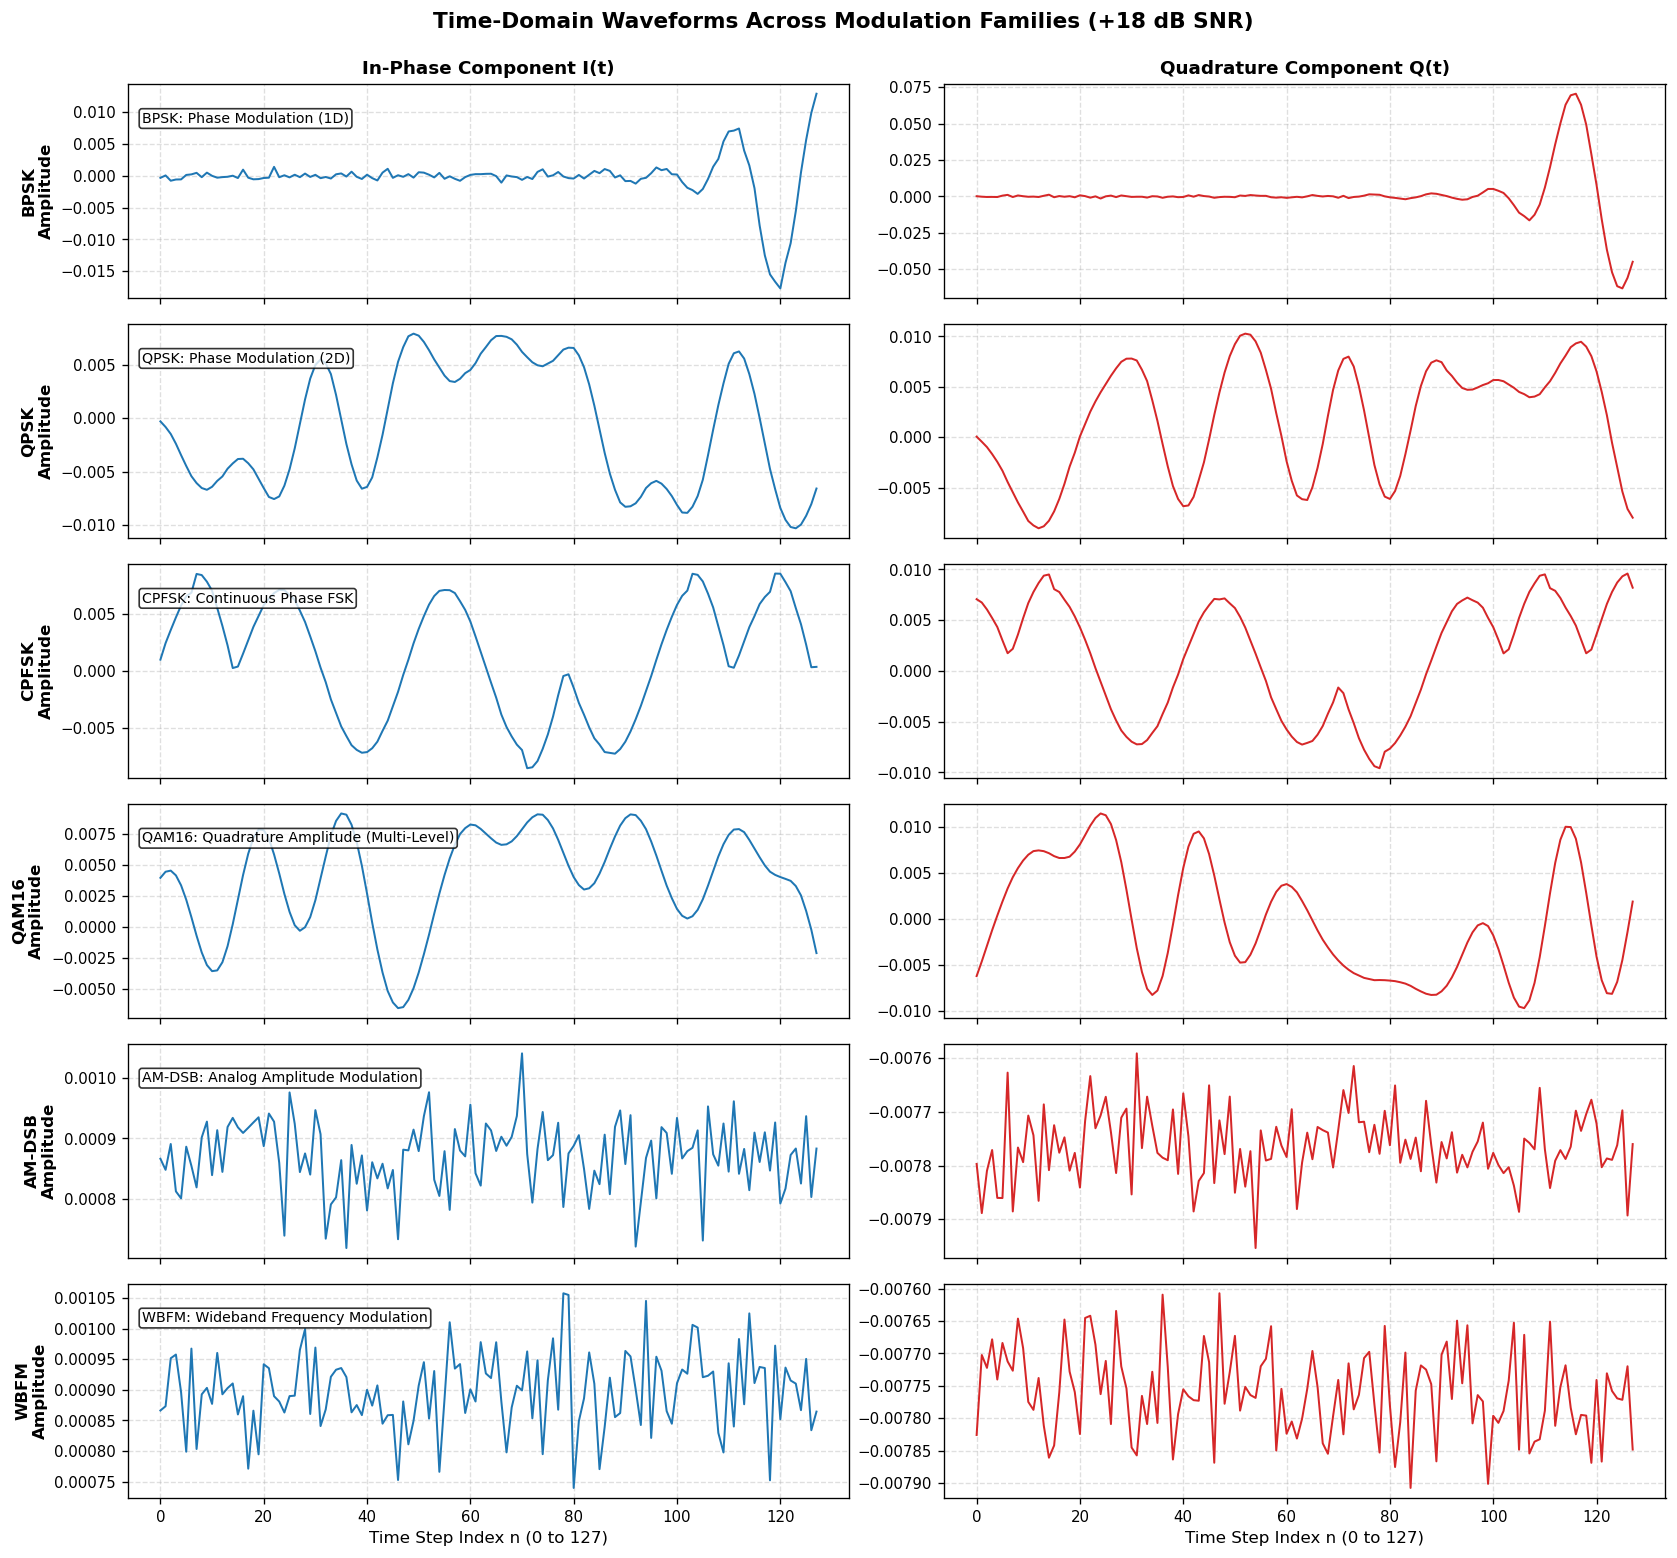

In [6]:
# Compare distinct modulation families in time domain at high SNR (+18 dB)
selected_family = [
    ('BPSK', 'Phase Modulation (1D)'),
    ('QPSK', 'Phase Modulation (2D)'),
    ('CPFSK', 'Continuous Phase FSK'),
    ('QAM16', 'Quadrature Amplitude (Multi-Level)'),
    ('AM-DSB', 'Analog Amplitude Modulation'),
    ('WBFM', 'Wideband Frequency Modulation')
]

fig, axes = plt.subplots(len(selected_family), 2, figsize=(14, 13), sharex=True)

time_steps = np.arange(128)

for i, (mod, desc) in enumerate(selected_family):
    frame = dataset[(mod, 18)][0]
    I_val = frame[0]
    Q_val = frame[1]
    
    # In-phase subplot
    ax_i = axes[i, 0]
    ax_i.plot(time_steps, I_val, color='#1f77b4', linewidth=1.2)
    ax_i.set_ylabel(f"{mod}\nAmplitude", fontweight='bold')
    ax_i.grid(True, alpha=0.4)
    if i == 0:
        ax_i.set_title("In-Phase Component I(t)", fontweight='bold')
    ax_i.text(0.02, 0.82, f"{mod}: {desc}", transform=ax_i.transAxes, 
              fontsize=8.5, bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8))
        
    # Quadrature subplot
    ax_q = axes[i, 1]
    ax_q.plot(time_steps, Q_val, color='#d62728', linewidth=1.2)
    ax_q.grid(True, alpha=0.4)
    if i == 0:
        ax_q.set_title("Quadrature Component Q(t)", fontweight='bold')

axes[-1, 0].set_xlabel("Time Step Index n (0 to 127)")
axes[-1, 1].set_xlabel("Time Step Index n (0 to 127)")

plt.suptitle("Time-Domain Waveforms Across Modulation Families (+18 dB SNR)", 
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


---
## 3. Constellation Diagrams ($I$-$Q$ Phase Space)

### 3.1 Mathematical Theory of Constellation Diagrams
A **constellation diagram** represents an RF signal on a two-dimensional Cartesian plane:
* **Horizontal Axis ($x$-axis)**: In-Phase component $I(t)$.
* **Vertical Axis ($y$-axis)**: Quadrature component $Q(t)$.

In ideal, noise-free digital communications sampled at optimal symbol instants $t = k T_{\text{sym}}$, each transmitted symbol $s_m$ corresponds to a unique geometric coordinate:
* **BPSK**: Two antipodal states on a line: $(+A, 0)$ and $(-A, 0)$.
* **QPSK**: Four states with equal magnitude: $(\pm A/\sqrt{2}, \pm A/\sqrt{2})$.
* **8PSK**: Eight states uniformly spaced on a circle with angular spacing $\Delta \theta = \pi/4$.
* **PAM4**: Four discrete amplitude states along a single 1D axis.
* **QAM16 / QAM64**: Two-dimensional $4 \times 4$ and $8 \times 8$ rectangular lattices with discrete amplitude and phase combinations.
* **CPFSK / GFSK / WBFM**: Constant envelope signals ($|s(t)| = \sqrt{I^2 + Q^2} \approx \text{const}$), producing circular trajectory rings in the $I$-$Q$ plane.

### 3.2 Channel Impairments in RadioML 2016.10a Constellations
In this synthetic dataset, constellation diagrams do not appear as simple stationary dots because realistic channel impairments are applied:
1. **Gaussian Noise Diffusion**: AWGN adds a bivariate 2D Gaussian random displacement vector to each point:
   $$\begin{bmatrix} I_{\text{obs}} \\ Q_{\text{obs}} \end{bmatrix} \sim \mathcal{N}\left( \begin{bmatrix} I_{\text{sym}} \\ Q_{\text{sym}} \end{bmatrix}, \frac{\sigma_w^2}{2} \mathbf{I}_2 \right)$$
2. **Carrier Frequency Offset (CFO)**: A residual mismatch between transmitter and receiver carrier frequencies multiplies the signal by $e^{j 2\pi \Delta f t}$, which causes the entire constellation to **rotate continuously over time**, transforming isolated constellation points into circular orbits or smeared rings!
3. **Pulse-Shaping Transitions**: Signals are sampled at multiple samples per symbol, capturing the trajectory between symbols rather than just the strobe instant.


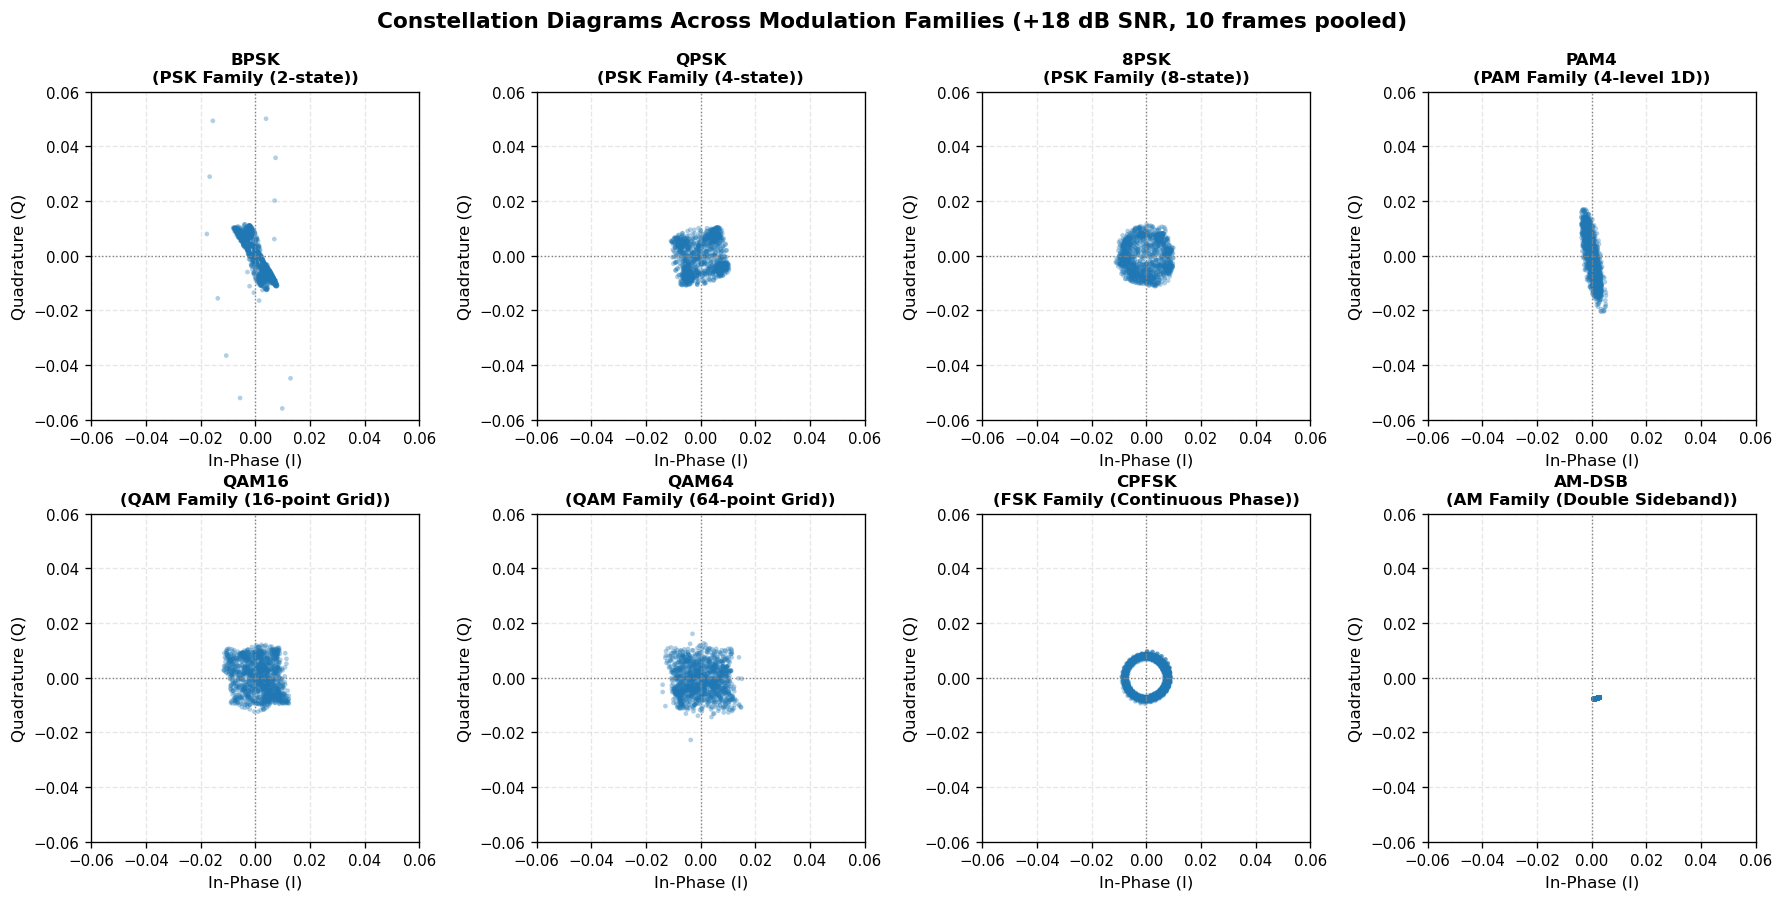

In [7]:
# Selected modulation schemes from each distinct family
family_showcase = [
    ('BPSK', 'PSK Family (2-state)'),
    ('QPSK', 'PSK Family (4-state)'),
    ('8PSK', 'PSK Family (8-state)'),
    ('PAM4', 'PAM Family (4-level 1D)'),
    ('QAM16', 'QAM Family (16-point Grid)'),
    ('QAM64', 'QAM Family (64-point Grid)'),
    ('CPFSK', 'FSK Family (Continuous Phase)'),
    ('AM-DSB', 'AM Family (Double Sideband)')
]

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
axes = axes.flatten()

# Pool multiple frames (10 frames = 1,280 samples) to visualize state attractors
n_frames_to_pool = 10

for idx, (mod, subtitle) in enumerate(family_showcase):
    ax = axes[idx]
    
    # Concatenate I and Q across pooled frames at pristine SNR (+18 dB)
    frames = dataset[(mod, 18)][:n_frames_to_pool]
    I_pooled = frames[:, 0, :].flatten()
    Q_pooled = frames[:, 1, :].flatten()
    
    # 2D Scatter plot
    ax.scatter(I_pooled, Q_pooled, alpha=0.35, s=8, color='#1f77b4', edgecolors='none')
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.axvline(0, color='gray', linestyle=':', linewidth=0.8)
    
    ax.set_title(f"{mod}\n({subtitle})", fontweight='bold', fontsize=10)
    ax.set_xlabel("In-Phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.set_xlim(-0.06, 0.06)
    ax.set_ylim(-0.06, 0.06)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)

plt.suptitle("Constellation Diagrams Across Modulation Families (+18 dB SNR, 10 frames pooled)", 
             fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


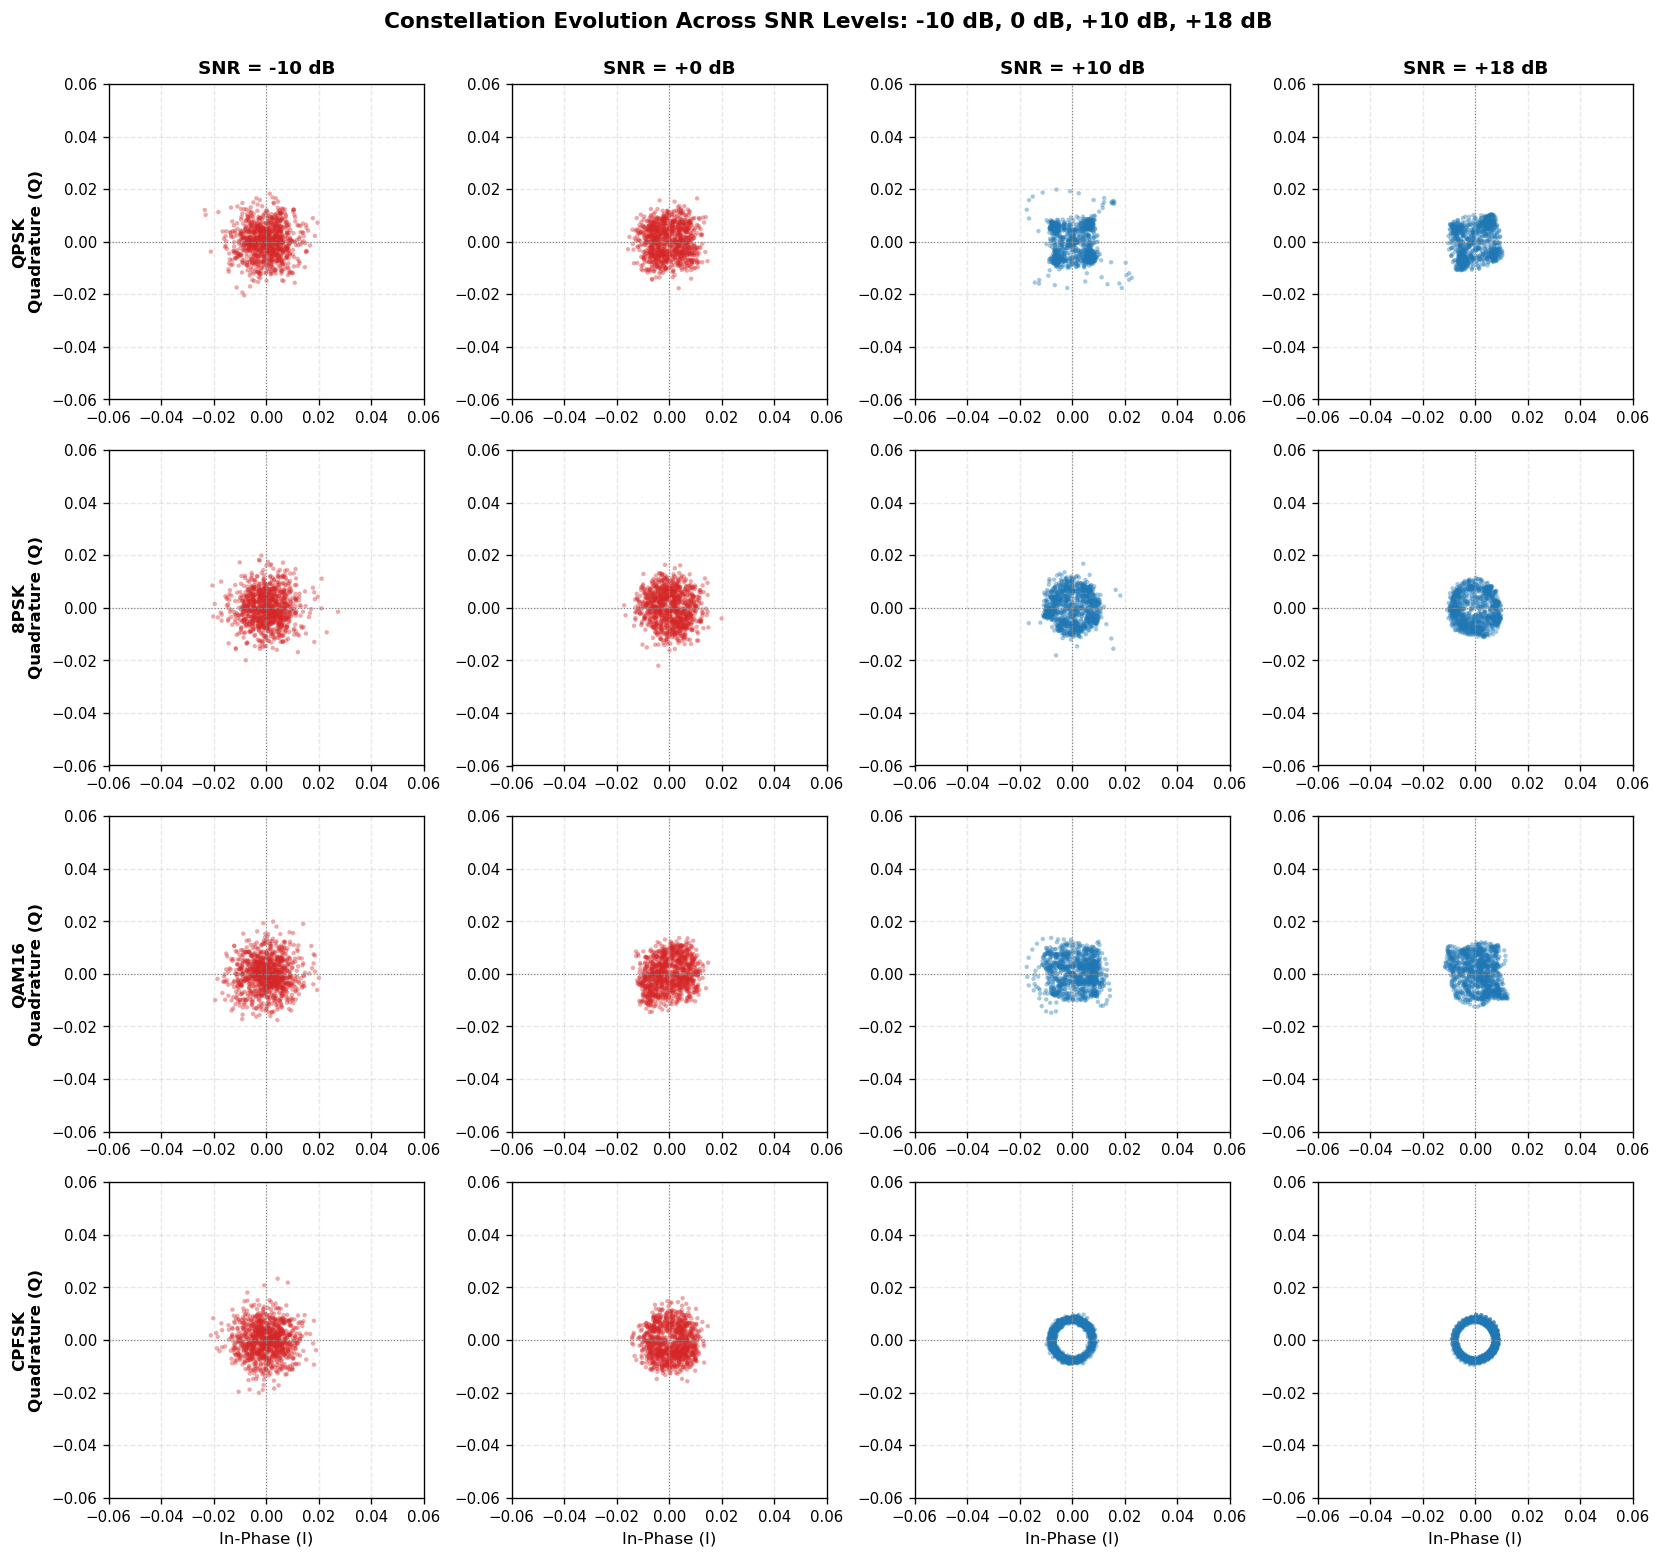

In [8]:
# Compare constellation dispersion across SNR levels for representative modulations
compare_mods = ['QPSK', '8PSK', 'QAM16', 'CPFSK']
compare_snrs = [-10, 0, 10, 18]
n_pool = 8

fig, axes = plt.subplots(len(compare_mods), len(compare_snrs), figsize=(14, 13))

for r, mod in enumerate(compare_mods):
    for c, snr in enumerate(compare_snrs):
        ax = axes[r, c]
        frames = dataset[(mod, snr)][:n_pool]
        I_pts = frames[:, 0, :].flatten()
        Q_pts = frames[:, 1, :].flatten()
        
        # Color coding: deeper blue for clean, red-tinted for noisy
        color = '#d62728' if snr <= 0 else '#1f77b4'
        ax.scatter(I_pts, Q_pts, alpha=0.4, s=7, color=color, edgecolors='none')
        ax.axhline(0, color='gray', linestyle=':', linewidth=0.7)
        ax.axvline(0, color='gray', linestyle=':', linewidth=0.7)
        
        ax.set_xlim(-0.06, 0.06)
        ax.set_ylim(-0.06, 0.06)
        ax.set_aspect('equal')
        ax.grid(True, alpha=0.3)
        
        # Row and column titles
        if r == 0:
            ax.set_title(f"SNR = {snr:+2d} dB", fontweight='bold', fontsize=11)
        if c == 0:
            ax.set_ylabel(f"{mod}\nQuadrature (Q)", fontweight='bold')
        if r == len(compare_mods) - 1:
            ax.set_xlabel("In-Phase (I)")

plt.suptitle("Constellation Evolution Across SNR Levels: -10 dB, 0 dB, +10 dB, +18 dB", 
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### 3.3 Physical Analysis of Constellation Dispersion & Decision Boundary Collapse

The multi-SNR constellation evolution grid provides direct empirical proof of why AMC classification accuracy follows a characteristic sigmoidal curve:

1. **Gaussian Cloud Expansion**:
   * As SNR decreases from $+18\text{ dB}$ to $-10\text{ dB}$, the variance $\sigma_w^2$ of the 2D Gaussian distribution increases exponentially.
   * At $+18\text{ dB}$, points are tightly clustered near their legitimate symbol trajectories.
   * At $0\text{ dB}$, the standard deviation of noise becomes comparable to the inter-symbol Euclidean distance:
     $$\sigma_w \approx d_{\text{min}} / 2$$
   * At $-10\text{ dB}$, the Gaussian clouds of individual symbols merge completely into an amorphous, isotropic 2D Gaussian bell centered at the origin.

2. **Vulnerability of Higher-Order Constellations**:
   * For **BPSK and QPSK**, the minimum distance $d_{\text{min}}$ between constellation points is large. Consequently, their clusters remain partially separable down to moderate SNRs ($0\text{ dB}$).
   * In contrast, for dense constellations like **QAM16 and QAM64**, points are packed much closer together for a normalized total power constraint. A modest amount of noise immediately causes adjacent decision regions to overlap, leading to misclassifications between QAM16 and QAM64 even at intermediate SNRs.

3. **Phase Rotation and Constant Envelope**:
   * For **CPFSK**, the continuous phase trajectory forms a distinct circular doughnut ring because the signal amplitude is constant ($A(t) \approx \text{const}$).
   * As noise increases, this ring broadens into a thick disk, losing its hollow center at $-10\text{ dB}$.


---
## 4. Frequency-Domain Visualization (Fast Fourier Transform - FFT)

### 4.1 Complex Baseband Discrete Fourier Transform
To inspect the spectral characteristics of the intercepted I/Q signals, we apply the **Discrete Fourier Transform (DFT)** via the Fast Fourier Transform (FFT) algorithm to the complex baseband representation:

$$s[n] = I[n] + j Q[n], \quad n \in [0, N-1]$$

The $N$-point DFT is given by:

$$S[k] = \sum_{n=0}^{N-1} s[n] e^{-j 2\pi \frac{k n}{N}}, \quad k \in \left[-\frac{N}{2}, \frac{N}{2} - 1\right]$$

Applying `fftshift` shifts the zero-frequency component (DC) to the center of the spectrum:
* The center frequency index $k = 0$ corresponds to the nominal RF carrier $f_c$ translated to baseband ($0\text{ Hz}$).
* The frequency axis is normalized relative to the sampling rate $f_s$:
  $$f_{\text{norm}} = \frac{f}{f_s} \in [-0.5, +0.5]$$

### 4.2 Magnitude Spectrum and Power Spectral Density
The magnitude spectrum in decibels is calculated as:

$$|S(f)|_{\text{dB}} = 20 \log_{10}\left(|S[k]| + \epsilon\right)$$

where $\epsilon = 10^{-12}$ prevents numerical underflow ($-\infty$).

Unlike real signals whose Fourier transforms are strictly Hermitian symmetric ($|X(-f)| = |X(f)|$), **complex baseband signals can have asymmetric spectra**. Positive frequencies correspond to frequencies above the RF carrier ($f_c + \Delta f$), while negative frequencies correspond to frequencies below the RF carrier ($f_c - \Delta f$).


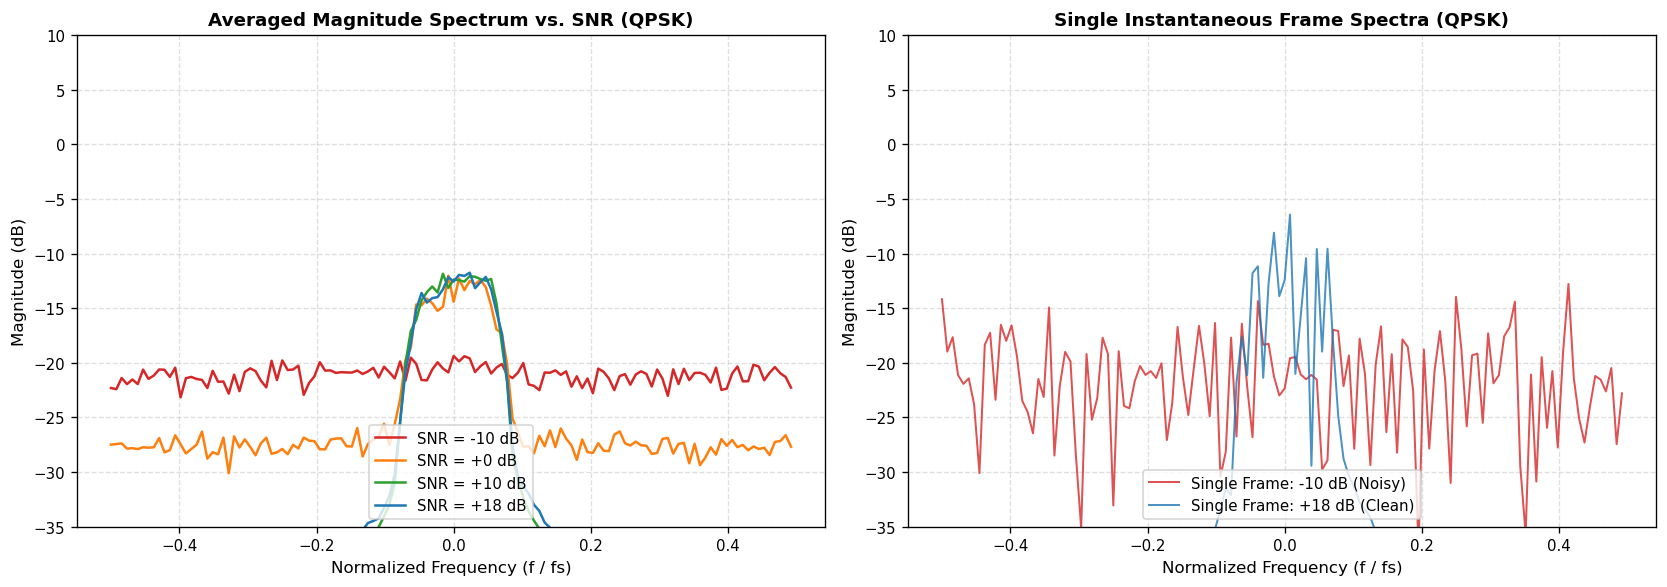

In [9]:
target_mod_fft = 'QPSK'
target_snrs_fft = [-10, 0, 10, 18]
n_fft = 128
freq_axis = np.fft.fftshift(np.fft.fftfreq(n_fft, d=1.0))  # Normalized frequency: -0.5 to +0.5

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Subplot: Overlay of Spectra Across SNRs
ax1 = axes[0]
colors_snr = {-10: '#d62728', 0: '#ff7f0e', 10: '#2ca02c', 18: '#1f77b4'}

for snr in target_snrs_fft:
    # Average magnitude spectrum over 50 independent frames to reduce spectral variance
    frames = dataset[(target_mod_fft, snr)][:50]
    complex_signals = frames[:, 0, :] + 1j * frames[:, 1, :]
    specs = np.abs(np.fft.fftshift(np.fft.fft(complex_signals, axis=1), axes=1))
    avg_mag_db = 20 * np.log10(np.mean(specs, axis=0) + 1e-12)
    
    ax1.plot(freq_axis, avg_mag_db, label=f"SNR = {snr:+2d} dB", 
             color=colors_snr[snr], linewidth=1.5)

ax1.set_title(f"Averaged Magnitude Spectrum vs. SNR ({target_mod_fft})", fontweight='bold')
ax1.set_xlabel("Normalized Frequency (f / fs)")
ax1.set_ylabel("Magnitude (dB)")
ax1.grid(True, alpha=0.4)
ax1.legend(loc='lower center')
ax1.set_ylim(-35, 10)

# Right Subplot: Single Frame Comparison (-10 dB vs +18 dB)
ax2 = axes[1]
for snr, col, lbl in [(-10, '#d62728', 'Single Frame: -10 dB (Noisy)'), 
                      (18, '#1f77b4', 'Single Frame: +18 dB (Clean)')]:
    raw = dataset[(target_mod_fft, snr)][0]
    sig_c = raw[0] + 1j * raw[1]
    spec_single = np.abs(np.fft.fftshift(np.fft.fft(sig_c)))
    mag_db_single = 20 * np.log10(spec_single + 1e-12)
    ax2.plot(freq_axis, mag_db_single, color=col, alpha=0.8, linewidth=1.2, label=lbl)

ax2.set_title(f"Single Instantaneous Frame Spectra ({target_mod_fft})", fontweight='bold')
ax2.set_xlabel("Normalized Frequency (f / fs)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True, alpha=0.4)
ax2.legend(loc='lower center')
ax2.set_ylim(-35, 10)

plt.tight_layout()
plt.show()


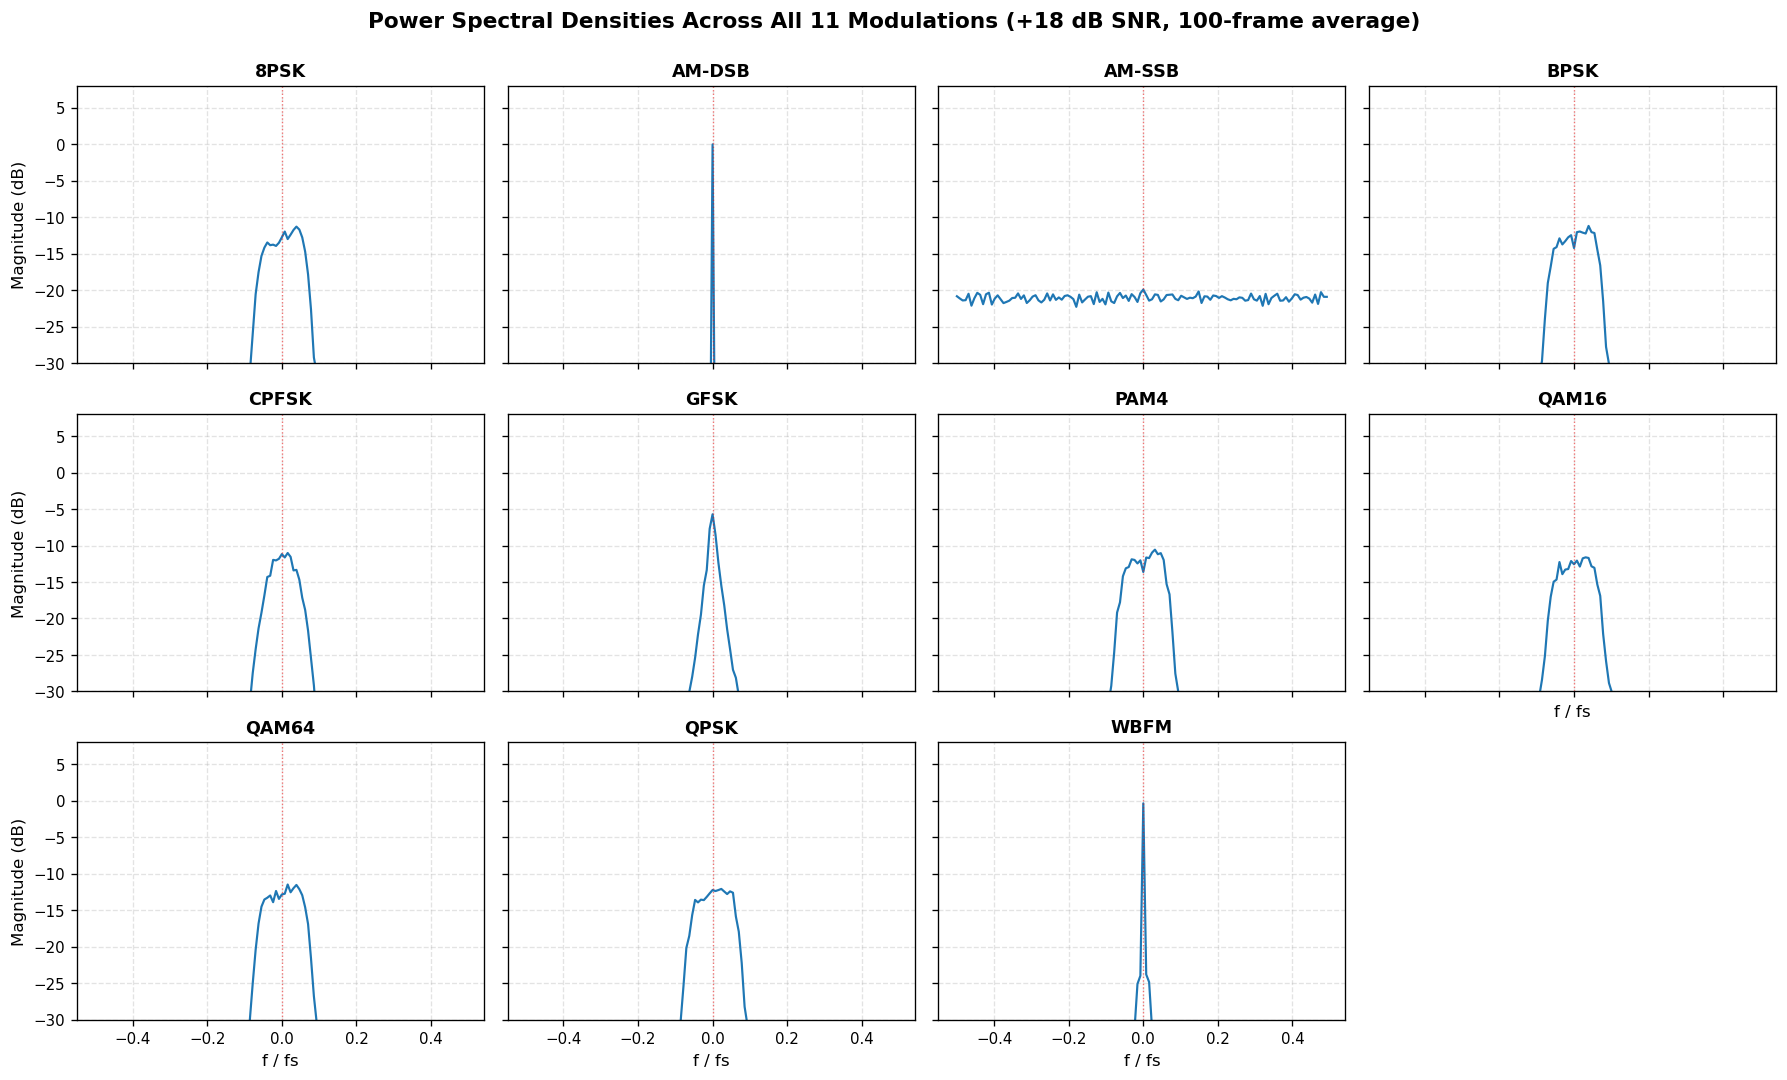

In [10]:
# Compute and plot magnitude spectra for all 11 modulation classes at +18 dB
fig, axes = plt.subplots(3, 4, figsize=(15, 9), sharex=True, sharey=True)
axes = axes.flatten()

n_avg_frames = 100

for idx, mod in enumerate(modulations):
    ax = axes[idx]
    
    # Average across frames for clean spectral estimation
    frames = dataset[(mod, 18)][:n_avg_frames]
    complex_sigs = frames[:, 0, :] + 1j * frames[:, 1, :]
    fft_vals = np.abs(np.fft.fftshift(np.fft.fft(complex_sigs, axis=1), axes=1))
    mean_spec_db = 20 * np.log10(np.mean(fft_vals, axis=0) + 1e-12)
    
    ax.plot(freq_axis, mean_spec_db, color='#1f77b4', linewidth=1.3)
    ax.axvline(0, color='red', linestyle=':', alpha=0.5, linewidth=0.8)
    ax.set_title(f"{mod}", fontweight='bold', fontsize=10.5)
    ax.set_ylim(-30, 8)
    ax.grid(True, alpha=0.35)
    
    if idx >= 7:
        ax.set_xlabel("f / fs")
    if idx % 4 == 0:
        ax.set_ylabel("Magnitude (dB)")

# Hide the unused 12th subplot
axes[11].axis('off')

plt.suptitle("Power Spectral Densities Across All 11 Modulations (+18 dB SNR, 100-frame average)", 
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


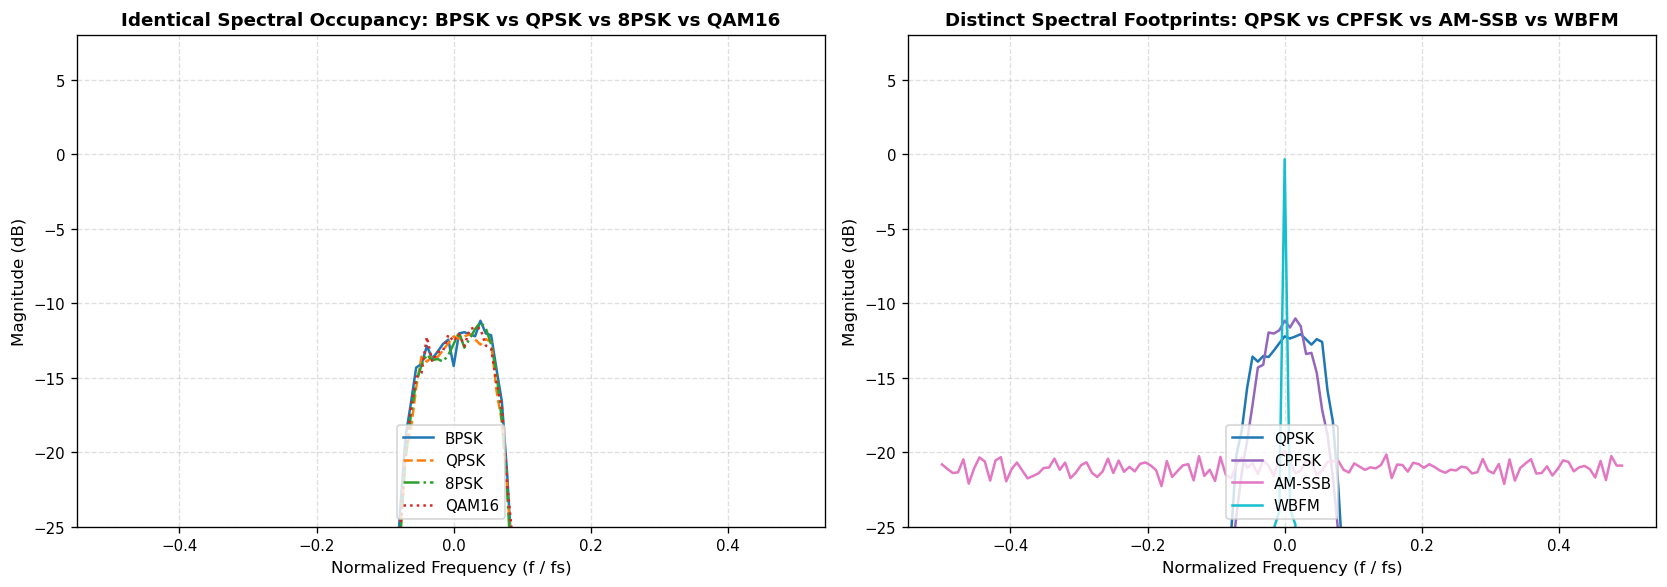

In [11]:
# Direct Overlay Comparisons illustrating spectral similarity vs. distinctiveness
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Digital Linear Modulations (RRC pulse shaped)
ax1 = axes[0]
for mod, col, ls in [('BPSK', '#1f77b4', '-'), ('QPSK', '#ff7f0e', '--'), 
                     ('8PSK', '#2ca02c', '-.'), ('QAM16', '#d62728', ':')]:
    frames = dataset[(mod, 18)][:100]
    c_sig = frames[:, 0, :] + 1j * frames[:, 1, :]
    spec = np.mean(np.abs(np.fft.fftshift(np.fft.fft(c_sig, axis=1), axes=1)), axis=0)
    ax1.plot(freq_axis, 20 * np.log10(spec + 1e-12), label=mod, color=col, linestyle=ls, linewidth=1.5)

ax1.set_title("Identical Spectral Occupancy: BPSK vs QPSK vs 8PSK vs QAM16", fontweight='bold')
ax1.set_xlabel("Normalized Frequency (f / fs)")
ax1.set_ylabel("Magnitude (dB)")
ax1.grid(True, alpha=0.4)
ax1.legend(loc='lower center')
ax1.set_ylim(-25, 8)

# Subplot 2: Diverse Families with Distinct Spectral Shapes
ax2 = axes[1]
for mod, col in [('QPSK', '#1f77b4'), ('CPFSK', '#9467bd'), 
                 ('AM-SSB', '#e377c2'), ('WBFM', '#17becf')]:
    frames = dataset[(mod, 18)][:100]
    c_sig = frames[:, 0, :] + 1j * frames[:, 1, :]
    spec = np.mean(np.abs(np.fft.fftshift(np.fft.fft(c_sig, axis=1), axes=1)), axis=0)
    ax2.plot(freq_axis, 20 * np.log10(spec + 1e-12), label=mod, color=col, linewidth=1.5)

ax2.set_title("Distinct Spectral Footprints: QPSK vs CPFSK vs AM-SSB vs WBFM", fontweight='bold')
ax2.set_xlabel("Normalized Frequency (f / fs)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True, alpha=0.4)
ax2.legend(loc='lower center')
ax2.set_ylim(-25, 8)

plt.tight_layout()
plt.show()


### 4.3 Critical Analysis: Is FFT Magnitude Alone Sufficient for AMC?

A fundamental question in modulation recognition is: **Can a classifier rely exclusively on the frequency domain (FFT magnitude)?**

Our spectral plots provide an unambiguous answer: **No, FFT magnitude alone is fundamentally insufficient.**

#### 1. Why FFT Succeeds for Family-Level Discrimination:
* **Analog vs. Digital Differentiation**: Wideband Frequency Modulation (`WBFM`) occupies a substantially wider spectral bandwidth than narrowband digital transmissions (governed by Carson's rule).
* **Single-Sideband Detection (`AM-SSB`)**: AM-SSB concentrates almost all spectral energy on one side of the carrier ($f > 0$), producing a starkly asymmetric spectrum that distinguishes it immediately from double-sideband (`AM-DSB`).
* **Continuous Phase FSK (`CPFSK`)**: The continuous frequency-shifting mechanism produces distinctive frequency deviations and spectral tone peaks.

#### 2. Why FFT Completely Fails for Intra-Family Classification:
* **Phase Blindness**: The Fourier magnitude spectrum $|S(f)| = |\mathcal{F}\{s(t)\}|$ **discards phase information** $\angle S(f)$.
* **Identical Spectral Profiles in PSK and QAM**: As clearly demonstrated in the left overlay plot above:
  * `BPSK`, `QPSK`, `8PSK`, and `QAM16` share identical pulse-shaping filters (Root-Raised Cosine, RRC) and identical symbol rates.
  * Their Power Spectral Densities (PSD) are virtually **indistinguishable**!
  * The difference between BPSK (2 phase states), QPSK (4 phase states), and 8PSK (8 phase states) resides purely in the **phase domain**, which the magnitude spectrum completely collapses.
  * The difference between QAM16 and QAM64 resides in their multi-level 2D grid coordinates, which have the same spectral envelope.

#### Conclusion:
While the frequency domain provides useful coarse-grained features (bandwidth, carrier offsets, spectral asymmetry), **fine-grained AMC requires joint phase, amplitude, and temporal trajectory modeling**, which is naturally captured in the raw two-channel $(2, 128)$ I/Q representation.


---
## 5. Scientific Interpretation & Relevance to Deep Learning AMC

### 5.1 Synthesis of Exploratory Findings
Our systematic investigation of RadioML 2016.10a across the Time, Constellation, and Frequency domains establishes key physical principles:

1. **Information Completeness of I/Q Baseband**:
   * Storing raw In-Phase ($I$) and Quadrature ($Q$) components preserves both instantaneous envelope $A(t) = \sqrt{I^2 + Q^2}$ and instantaneous phase $\phi(t) = \arctan2(Q, I)$.
   * This retains the full analytic signal without requiring excessive GHz-rate sampling of the RF carrier.

2. **The Three SNR Regimes in AMC**:
   * **Low SNR ($< 0\text{ dB}$)**: Noise power dominates ($P_w \ge P_s$). Time waveforms are stochastic noise; constellations collapse into a single bivariate Gaussian blob; FFT spectra are submerged in the noise floor. Classification accuracy inevitably approaches random guessing ($1/11 \approx 9.1\%$).
   * **Transition Zone ($0\text{ dB}$ to $+6\text{ dB}$)**: Signal power surpasses noise. Constellation attractors separate; characteristic pulse transitions emerge. Deep learning accuracy experiences a rapid sigmoidal ascent.
   * **High SNR ($> +10\text{ dB}$)**: Inter-symbol distance $d_{\text{min}} \gg \sigma_w$. Accuracy plateaus, with residual errors primarily driven by channel impairments (carrier frequency offset, phase jitter) and subtle intra-family ambiguities (e.g., QAM16 vs. QAM64, WBFM vs. AM-DSB).

3. **Inadequacy of Isolated Single-Domain Features**:
   * Time-domain amplitude alone cannot resolve phase modulations.
   * Constellation points alone (without temporal tracking) are vulnerable to continuous carrier frequency offset rotations.
   * Frequency-domain magnitude alone is blind to phase shifts and multi-level amplitude grids.

### 5.2 Direct Implications for Neural Network Architecture Design
These findings provide the theoretical justification for why modern Deep Learning models excel at Automatic Modulation Classification:

* **1D Convolutional Neural Networks (CNNs)** (e.g., VT-CNN2, ResNet-1D):
  * By treating the signal as a tensor of shape `(2, 128)` (2 channels: $I$ and $Q$; length: 128), 1D convolutional kernels slide across time.
  * The network automatically learns matched filters, differential phase detectors, and envelope detectors directly from raw data without manual expert feature engineering.
* **Complex-Valued Neural Networks (CVNNs)**:
  * Operations respecting complex algebra ($s = I + jQ$) preserve phase rotation arithmetic ($e^{j\theta}$) inherently.
* **Recurrent Architectures & Transformers (LSTM / GRU / Attention)**:
  * Because CFO induces a time-varying phase rotation $\Delta \theta(t) = 2\pi \Delta f t$, sequence models capable of tracking temporal state across the 128 time steps can track phase drift and symbol transitions over time.

---
### Next Steps in the AMC Project Pipeline
Having completed this exploratory data analysis:
1. **Data Preprocessing & Partitioning**: Structure the dataset into train/validation/test splits stratified by modulation and SNR.
2. **Model Implementation**: Implement baseline deep learning architectures (e.g., VT-CNN2, ResNet, CLDNN).
3. **SNR-Stratified Evaluation**: Train classifiers and evaluate classification accuracy curves $P_{cc}(\text{SNR})$ across all 20 SNR levels.
